# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import re
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from pathlib import Path

# Reproducible results
torch.manual_seed(42)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.10.0+cpu


## Step 2 — Upload the dataset

Keep `Lab_11_QnA_Dataset.csv` in the same folder as this notebook. The code below also checks the Google Colab `/content` folder and will prompt for an upload if the dataset is not found.

In [2]:
# Find the uploaded CSV file
possible_paths = [
    Path("Lab_11_QnA_Dataset.csv"),
    Path("/content/Lab_11_QnA_Dataset.csv"),
    Path("/mnt/data/Lab_11_QnA_Dataset.csv"),
]

DATA_PATH = next((path for path in possible_paths if path.exists()), None)

if DATA_PATH is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        uploaded_name = next(iter(uploaded))
        DATA_PATH = Path(uploaded_name)
    except ImportError as exc:
        raise FileNotFoundError(
            "Lab_11_QnA_Dataset.csv was not found. Put it next to this notebook."
        ) from exc

df = pd.read_csv(DATA_PATH)

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
# 1. Lowercase and remove punctuation
def clean_text(text):
    return re.sub(r"[^\w\s]", "", str(text).lower()).strip()

df["clean_question"] = df["question"].apply(clean_text)

# 2. Build a vocabulary: each word receives a unique integer
PAD_IDX = 0
UNK_IDX = 1
word_to_idx = {"<PAD>": PAD_IDX, "<UNK>": UNK_IDX}

tokenized_questions = [question.split() for question in df["clean_question"]]

for words in tokenized_questions:
    for word in words:
        if word not in word_to_idx:
            word_to_idx[word] = len(word_to_idx)

# 3. Convert words to numbers and pad every question to the same length
max_len = max(len(words) for words in tokenized_questions)

sequences = []
for words in tokenized_questions:
    sequence = [word_to_idx.get(word, UNK_IDX) for word in words]
    sequence = sequence[:max_len]
    sequence += [PAD_IDX] * (max_len - len(sequence))
    sequences.append(sequence)

# Convert questions and answer labels to PyTorch tensors
X = torch.tensor(sequences, dtype=torch.long)

# Map answer_id values to consecutive class indices
answer_ids = sorted(df["answer_id"].unique())
answer_to_idx = {answer_id: index for index, answer_id in enumerate(answer_ids)}
idx_to_answer_id = {index: answer_id for answer_id, index in answer_to_idx.items()}
y = torch.tensor(
    [answer_to_idx[answer_id] for answer_id in df["answer_id"]],
    dtype=torch.long
)

answer_text = (
    df.drop_duplicates("answer_id")
      .set_index("answer_id")["answer"]
      .to_dict()
)

print("Vocabulary size:", len(word_to_idx))
print("Maximum question length:", max_len)
print("Input tensor shape:", tuple(X.shape))
print("Target tensor shape:", tuple(y.shape))

Vocabulary size: 228
Maximum question length: 11
Input tensor shape: (168, 11)
Target tensor shape: (168,)


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word_to_idx), 16, padding_idx=PAD_IDX)
        self.rnn = nn.RNN(input_size=16, hidden_size=32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, len(answer_ids))

    def forward(self, x):
        embedded = self.emb(x)
        rnn_output, _ = self.rnn(embedded)

        # Calculate one attention score for each word
        scores = self.att(rnn_output).squeeze(-1)

        # Do not give attention to padding tokens
        scores = scores.masked_fill(x.eq(PAD_IDX), -1e9)

        # Convert scores into attention weights
        weights = torch.softmax(scores, dim=1)

        # Weighted sum of the RNN outputs
        context = (rnn_output * weights.unsqueeze(-1)).sum(dim=1)

        # Predict the answer group
        logits = self.fc(context)
        return logits, weights


model = RNN()
print(model)

RNN(
  (emb): Embedding(228, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
epochs = 150

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    predictions, attention_weights = model(X)
    loss = nn.functional.cross_entropy(predictions, y)

    loss.backward()
    optimizer.step()

model.eval()
with torch.no_grad():
    final_logits, _ = model(X)
    predicted_labels = final_logits.argmax(dim=1)
    training_accuracy = (predicted_labels == y).float().mean().item()

print("Training finished!")
print(f"Final training loss: {loss.item():.4f}")
print(f"Training accuracy: {training_accuracy * 100:.2f}%")

Training finished!
Final training loss: 0.0020
Training accuracy: 100.00%


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

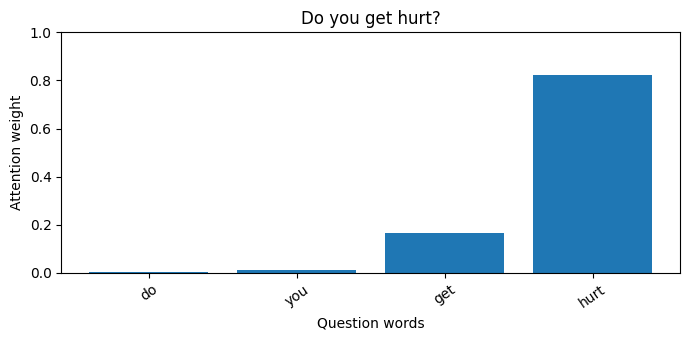

Question: Do you get hurt?
Highest-attention word: hurt
Predicted answer: I don't have a body.


In [6]:
def get_attention_details(question):
    # Clean and tokenize the new question
    clean_question = clean_text(question)
    words = clean_question.split()

    # Convert words to indices and pad to the training length
    sequence = [word_to_idx.get(word, UNK_IDX) for word in words[:max_len]]
    used_words = words[:max_len]
    sequence += [PAD_IDX] * (max_len - len(sequence))
    input_tensor = torch.tensor([sequence], dtype=torch.long)

    model.eval()
    with torch.no_grad():
        logits, weights = model(input_tensor)
        predicted_class = int(logits.argmax(dim=1).item())

    word_weights = weights[0, :len(used_words)].cpu().tolist()
    if not word_weights:
        raise ValueError("The question must contain at least one word.")

    top_position = int(max(range(len(word_weights)), key=word_weights.__getitem__))

    return {
        "words": used_words,
        "weights": word_weights,
        "top_word": used_words[top_position],
        "top_weight": word_weights[top_position],
        "predicted_answer_id": idx_to_answer_id[predicted_class],
    }


def plot_attention(question, ax=None, title=None):
    details = get_attention_details(question)

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3.5))

    ax.bar(details["words"], details["weights"])
    ax.set_title(title or question)
    ax.set_ylabel("Attention weight")
    ax.set_xlabel("Question words")
    ax.tick_params(axis="x", rotation=35)
    ax.set_ylim(0, 1)
    return details


# Example: visualize the first question
example_question = df.loc[0, "question"]
example_details = plot_attention(example_question)
plt.tight_layout()
plt.show()

print("Question:", example_question)
print("Highest-attention word:", example_details["top_word"])
print("Predicted answer:", answer_text[example_details["predicted_answer_id"]])

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: Do you get hurt?
Highest-attention word: 'hurt' (weight = 0.821)
Predicted answer: I don't have a body.
------------------------------------------------------------


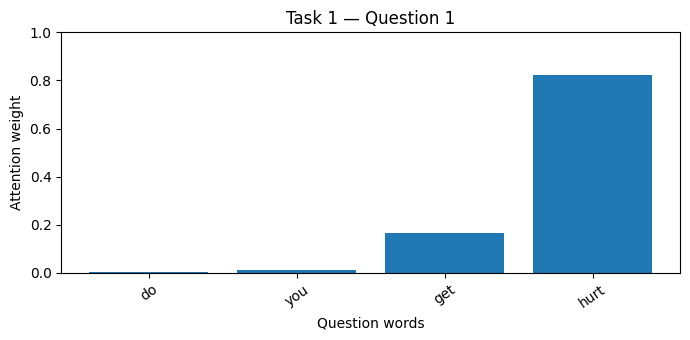

Question: Are you old?
Highest-attention word: 'old' (weight = 0.932)
Predicted answer: Age doesn't really apply to me.
------------------------------------------------------------


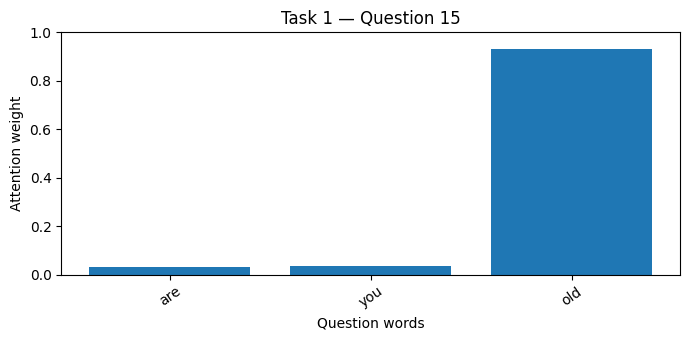

Question: Will you ask me anything about myself
Highest-attention word: 'myself' (weight = 0.341)
Predicted answer: I'm better at answering questions.
------------------------------------------------------------


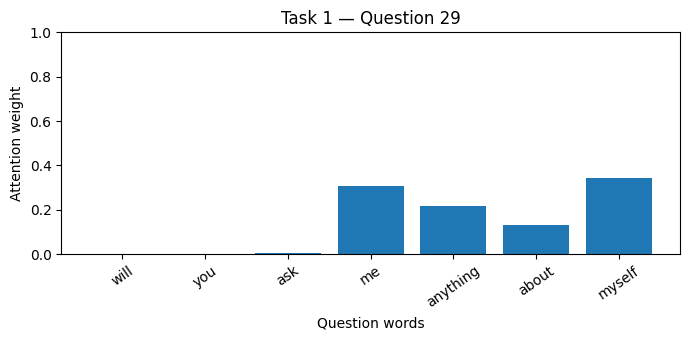

Highest-attention words: hurt, old, myself
Task 1 observation:
The highest-attention words in this run are meaningful clues to the questions: 'hurt' relates to physical condition, 'old' relates to age, and 'myself' relates to a question about the user. This suggests that attention often emphasizes words that help identify the topic or intent. However, the weights are learned associations from this small dataset; they do not prove that a word is objectively the most important part of a question.


In [7]:
# Select three questions from different answer groups
task1_indices = [0, 14, 28]
task1_results = []

for index in task1_indices:
    question = df.loc[index, "question"]
    details = plot_attention(question, title=f"Task 1 — Question {index + 1}")
    task1_results.append((question, details))

    print("Question:", question)
    print(
        f"Highest-attention word: '{details['top_word']}' "
        f"(weight = {details['top_weight']:.3f})"
    )
    print("Predicted answer:", answer_text[details["predicted_answer_id"]])
    print("-" * 60)
    plt.tight_layout()
    plt.show()
task1_top_words = [details["top_word"] for _, details in task1_results]
print("Highest-attention words:", ", ".join(task1_top_words))
print("Task 1 observation:")
print(
    "The highest-attention words in this run are meaningful clues to the "
    "questions: 'hurt' relates to physical condition, 'old' relates to age, "
    "and 'myself' relates to a question about the user. This suggests that "
    "attention often emphasizes words that help identify the topic or intent. "
    "However, the weights are learned associations from this small dataset; "
    "they do not prove that a word is objectively the most important part "
    "of a question."
)


Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

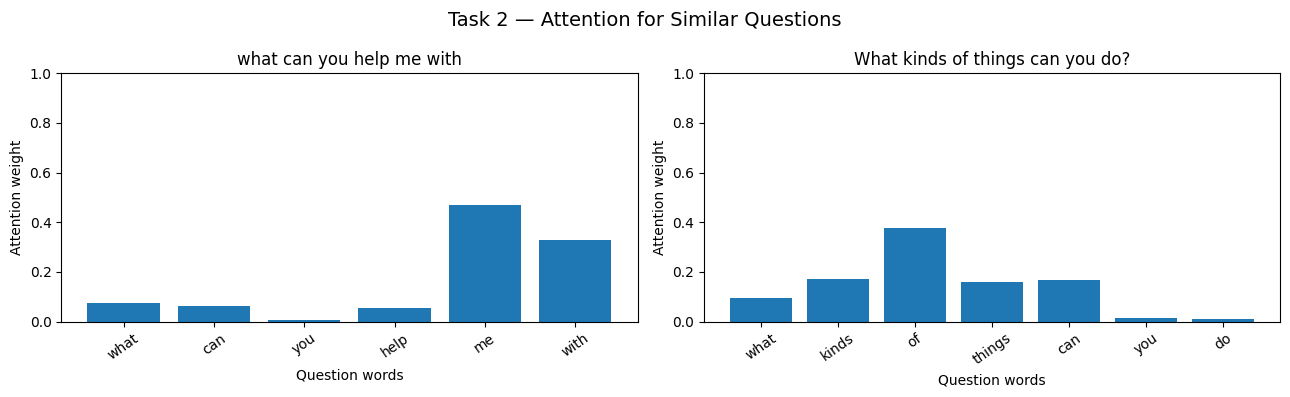

Question: what can you help me with
Highest-attention word: 'me' (weight = 0.470)
Predicted answer: I'm here to answer your questions and help out.
------------------------------------------------------------
Question: What kinds of things can you do?
Highest-attention word: 'of' (weight = 0.377)
Predicted answer: I'm here to answer your questions and help out.
------------------------------------------------------------
Both questions belong to answer group: 5 — I'm here to answer your questions and help out.
Highest-attention words: 'me' and 'of'
Task 2 observation:
In this run, the first question's highest-attention word is 'me', while the second question's is 'of'. Thus, the model focuses on different words even though both questions belong to the same answer group. Both questions are predicted as the same answer group. This suggests that attention is context-dependent and can respond to the wording of each input. The highest-weight word is not always the most meaningful word (it c

In [8]:
# Two differently worded questions from the same answer group
similar_questions = [
    df.loc[72, "question"],  # "what can you help me with"
    df.loc[81, "question"],  # "What kinds of things can you do?"
]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

task2_results = []
for question, ax in zip(similar_questions, axes):
    details = plot_attention(question, ax=ax, title=question)
    task2_results.append((question, details))

fig.suptitle("Task 2 — Attention for Similar Questions", fontsize=14)
fig.tight_layout()
plt.show()

for question, details in task2_results:
    print("Question:", question)
    print(
        f"Highest-attention word: '{details['top_word']}' "
        f"(weight = {details['top_weight']:.3f})"
    )
    print("Predicted answer:", answer_text[details["predicted_answer_id"]])
    print("-" * 60)

print(
    "Both questions belong to answer group:",
    df.loc[72, "answer_id"],
    "—",
    answer_text[df.loc[72, "answer_id"]]
)
task2_top_words = [details["top_word"] for _, details in task2_results]
print("Highest-attention words:", " and ".join(repr(word) for word in task2_top_words))
print("Task 2 observation:")
if task2_top_words[0] == task2_top_words[1]:
    comparison = (
        f"In this run, both questions receive their highest attention on "
        f"'{task2_top_words[0]}'. This suggests that the model is responding "
        "to a shared cue in the two differently worded questions."
    )
else:
    comparison = (
        f"In this run, the first question's highest-attention word is "
        f"'{task2_top_words[0]}', while the second question's is "
        f"'{task2_top_words[1]}'. Thus, the model focuses on different words "
        "even though both questions belong to the same answer group."
    )
print(
    comparison + " Both questions are predicted as the same answer group. "
    "This suggests that attention is context-dependent and can respond to "
    "the wording of each input. The highest-weight word is not always the "
    "most meaningful word (it can even be a function word), so attention "
    "weights should be treated as clues to the model's behavior rather "
    "than perfect explanations of its reasoning."
)
